# Day 4: Delivery Time Prediction Using Regression

## Objective

The objective of this analysis is to predict delivery time in minutes using order and delivery information from the Uber Eats synthetic dataset.

The analysis will:
- Load and combine relevant datasets.
- Clean data and prepare features.
- Establish a baseline prediction.
- Train Random Forest, Ridge Regression, and Lasso Regression models.
- Evaluate model performance using MAE, RMSE, and R².
- Identify important predictive features.
- Visualize actual and predicted delivery times.
- Provide business recommendations based on the findings.

**Target variable:** `delivery_time_minutes`

**Tools:** Python, Pandas, Matplotlib, Scikit-learn.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge, Lasso
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", None)

PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "data" / "raw").exists():
    PROJECT_DIR = Path.home() / "Projects" / "uber-eats-intelligence"

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
INSIGHTS_DIR = PROJECT_DIR / "reports" / "insights"
MODELS_DIR = PROJECT_DIR / "models"

for folder in [PROCESSED_DIR, FIGURES_DIR, INSIGHTS_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)

Project directory: /home/nineleaps/Projects/uber-eats-intelligence


In [2]:
orders = pd.read_csv(RAW_DIR / "orders.csv")
deliveries = pd.read_csv(RAW_DIR / "deliveries.csv")
restaurants = pd.read_csv(RAW_DIR / "restaurants.csv")

print("Orders shape:", orders.shape)
print("Deliveries shape:", deliveries.shape)
print("Restaurants shape:", restaurants.shape)

print("\nDelivery columns:")
print(deliveries.columns.tolist())

print("\nOrder columns:")
print(orders.columns.tolist())

print("\nRestaurant columns:")
print(restaurants.columns.tolist())

Orders shape: (5000, 7)
Deliveries shape: (5000, 8)
Restaurants shape: (60, 5)

Delivery columns:
['delivery_id', 'order_id', 'driver_id', 'delivery_distance_km', 'preparation_time_minutes', 'delivery_time_minutes', 'weather', 'traffic_condition']

Order columns:
['order_id', 'customer_id', 'restaurant_id', 'order_timestamp', 'order_amount', 'number_of_items', 'order_status']

Restaurant columns:
['restaurant_id', 'restaurant_name', 'category', 'city', 'restaurant_rating']


## Data Preparation and Feature Engineering

We will combine delivery records with order and restaurant information using their identifiers. The target is `delivery_time_minutes`.

Potential predictors include delivery distance, preparation time, weather, traffic, order amount, number of items, order hour, weekend indicator, restaurant category, and restaurant city.

Identifiers will not be used as predictive features. The target column will also be kept separate to prevent it from accidentally entering the input features.

In [3]:
# Join deliveries with orders
model_data = deliveries.merge(
    orders,
    on="order_id",
    how="inner",
    validate="one_to_one"
)

# Add restaurant information
model_data = model_data.merge(
    restaurants[
        ["restaurant_id", "category", "city"]
    ],
    on="restaurant_id",
    how="left",
    validate="many_to_one"
)

print("Combined dataset shape:", model_data.shape)
print("\nCombined columns:")
print(model_data.columns.tolist())

print("\nFirst five rows:")
print(model_data.head())

Combined dataset shape: (5000, 16)

Combined columns:
['delivery_id', 'order_id', 'driver_id', 'delivery_distance_km', 'preparation_time_minutes', 'delivery_time_minutes', 'weather', 'traffic_condition', 'customer_id', 'restaurant_id', 'order_timestamp', 'order_amount', 'number_of_items', 'order_status', 'category', 'city']

First five rows:
   delivery_id  order_id  driver_id  delivery_distance_km  \
0            1         1         94                  5.96   
1            2         2         22                 11.47   
2            3         3         44                  2.07   
3            4         4         60                 12.87   
4            5         5         53                  0.92   

   preparation_time_minutes  delivery_time_minutes weather traffic_condition  \
0                        18                   32.4   Clear            Medium   
1                        37                   75.6     Hot              High   
2                        19                   39.

In [4]:
print("Missing values:")
print(model_data.isnull().sum())

print("\nDuplicate rows:", model_data.duplicated().sum())

print("\nTarget summary:")
print(model_data["delivery_time_minutes"].describe())

print("\nInvalid or missing target values:")
print(
    model_data["delivery_time_minutes"].isna().sum()
    + (model_data["delivery_time_minutes"] <= 0).sum()
)

Missing values:
delivery_id                 0
order_id                    0
driver_id                   0
delivery_distance_km        0
preparation_time_minutes    0
delivery_time_minutes       0
weather                     0
traffic_condition           0
customer_id                 0
restaurant_id               0
order_timestamp             0
order_amount                0
number_of_items             0
order_status                0
category                    0
city                        0
dtype: int64

Duplicate rows: 0

Target summary:
count    5000.000000
mean       53.684200
std        14.633875
min        11.300000
25%        43.200000
50%        53.600000
75%        64.000000
max        98.000000
Name: delivery_time_minutes, dtype: float64

Invalid or missing target values:
0


In [5]:
# Convert timestamp and numeric columns
model_data["order_timestamp"] = pd.to_datetime(
    model_data["order_timestamp"],
    errors="coerce"
)

numeric_columns = [
    "delivery_time_minutes",
    "delivery_distance_km",
    "preparation_time_minutes",
    "order_amount",
    "number_of_items"
]

for column in numeric_columns:
    model_data[column] = pd.to_numeric(
        model_data[column],
        errors="coerce"
    )

# Create time-based features
model_data["order_hour"] = model_data["order_timestamp"].dt.hour

model_data["is_weekend"] = (
    model_data["order_timestamp"].dt.dayofweek >= 5
).astype(float)

# Remove rows without a valid target
model_data = model_data[
    model_data["delivery_time_minutes"].notna()
    & (model_data["delivery_time_minutes"] > 0)
].copy()

# Exclude records where core order or delivery data is unavailable
model_data = model_data.dropna(
    subset=["order_timestamp"]
).copy()

feature_columns = [
    "delivery_distance_km",
    "preparation_time_minutes",
    "order_amount",
    "number_of_items",
    "order_hour",
    "is_weekend",
    "weather",
    "traffic_condition",
    "category",
    "city"
]

X = model_data[feature_columns].copy()
y = model_data["delivery_time_minutes"].copy()

numeric_features = [
    "delivery_distance_km",
    "preparation_time_minutes",
    "order_amount",
    "number_of_items",
    "order_hour",
    "is_weekend"
]

categorical_features = [
    "weather",
    "traffic_condition",
    "category",
    "city"
]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget statistics:")
print(y.describe())

Features shape: (5000, 10)
Target shape: (5000,)

Target statistics:
count    5000.000000
mean       53.684200
std        14.633875
min        11.300000
25%        43.200000
50%        53.600000
75%        64.000000
max        98.000000
Name: delivery_time_minutes, dtype: float64


/tmp/ipykernel_69787/540954686.py:25: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  model_data["order_timestamp"].dt.dayofweek >= 5


## Training and Testing Data

We will divide the data into training and testing sets. The training set is used to fit the models, while the test set evaluates how well they predict previously unseen observations.

A fixed random state makes the split reproducible. For this initial regression exercise, we use an 80% training and 20% testing split. A chronological split would be preferable if the main goal were to simulate future delivery predictions.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training target mean:", round(y_train.mean(), 2))
print("Testing target mean:", round(y_test.mean(), 2))

Training rows: 4000
Testing rows: 1000
Training target mean: 53.72
Testing target mean: 53.54


In [7]:
numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, numeric_features),
        ("categorical", categorical_preprocessor, categorical_features)
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


## Baseline Regression Model

A baseline model predicts the mean delivery time from the training set for every test observation. It provides a simple reference point.

The more advanced models should ideally improve upon this baseline. If a model does not improve the prediction errors, its added complexity may not be worthwhile.

In [8]:
models = {
    "Baseline": DummyRegressor(strategy="mean"),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        min_samples_leaf=2,
        n_jobs=-1
    ),

    "Ridge Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", Ridge(alpha=1.0))
    ]),

    "Lasso Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", Lasso(alpha=0.01, max_iter=10000))
    ])
}

results = []
predictions = {}

for model_name, model in models.items():
    if model_name == "Random Forest":
        model_pipeline = Pipeline(steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ])
    else:
        model_pipeline = model

    model_pipeline.fit(X_train, y_train)
    y_prediction = model_pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_prediction)
    rmse = np.sqrt(mean_squared_error(y_test, y_prediction))
    r2 = r2_score(y_test, y_prediction)

    results.append({
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    predictions[model_name] = y_prediction
    models[model_name] = model_pipeline

results_df = pd.DataFrame(results).sort_values("RMSE")

print(results_df.round(3))

              Model     MAE    RMSE     R2
3  Lasso Regression   4.121   5.190  0.872
2  Ridge Regression   4.122   5.195  0.872
1     Random Forest   4.447   5.536  0.855
0          Baseline  11.778  14.525 -0.000


In [9]:
results_df.to_csv(
    INSIGHTS_DIR / "regression_model_comparison.csv",
    index=False
)

print("Saved regression_model_comparison.csv")

Saved regression_model_comparison.csv


## Regression Model Comparison

We will visualize the MAE of the four models to compare their typical prediction errors. The model with the lowest MAE has the smallest average absolute error on the test set. We will also consider RMSE and R² before selecting a final model.

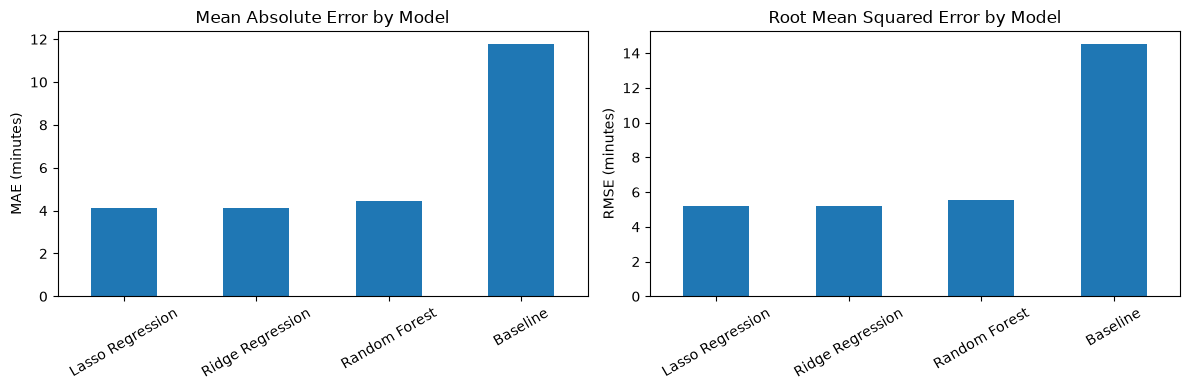

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

results_df.sort_values("MAE").plot(
    x="Model",
    y="MAE",
    kind="bar",
    ax=axes[0],
    legend=False
)
axes[0].set_title("Mean Absolute Error by Model")
axes[0].set_ylabel("MAE (minutes)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=30)

results_df.sort_values("RMSE").plot(
    x="Model",
    y="RMSE",
    kind="bar",
    ax=axes[1],
    legend=False
)
axes[1].set_title("Root Mean Squared Error by Model")
axes[1].set_ylabel("RMSE (minutes)")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "regression_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [11]:
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

print("Best model by test MAE:", best_model_name)
print(results_df.iloc[0])

Best model by test MAE: Lasso Regression
Model    Lasso Regression
MAE               4.12131
RMSE             5.189735
R2               0.872315
Name: 3, dtype: object


## Actual vs Predicted Delivery Time

This visualization compares actual delivery times with the predictions from the selected model.

Points close to the diagonal line represent more accurate predictions. Points far from the line indicate larger prediction errors. The visualization helps identify whether the model struggles with particularly short or long deliveries.

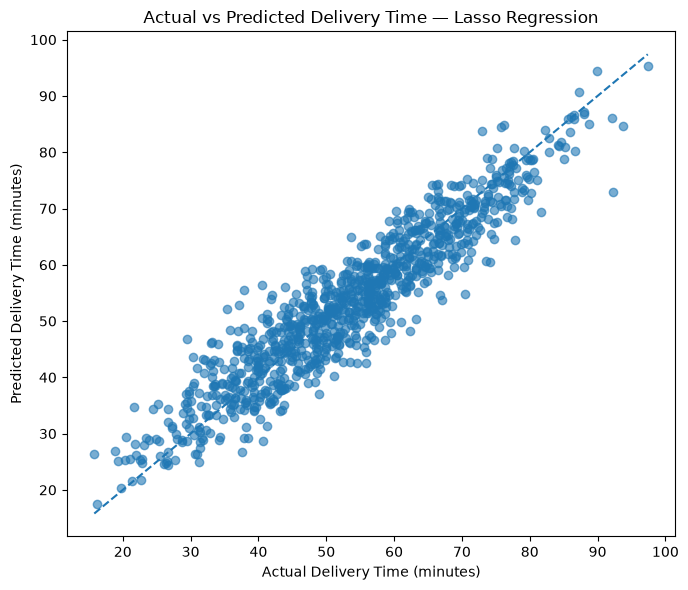

In [12]:
best_predictions = predictions[best_model_name]

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_predictions, alpha=0.6)

lower_bound = min(y_test.min(), best_predictions.min())
upper_bound = max(y_test.max(), best_predictions.max())

plt.plot(
    [lower_bound, upper_bound],
    [lower_bound, upper_bound],
    linestyle="--"
)

plt.xlabel("Actual Delivery Time (minutes)")
plt.ylabel("Predicted Delivery Time (minutes)")
plt.title(f"Actual vs Predicted Delivery Time — {best_model_name}")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "actual_vs_predicted_delivery_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [13]:
prediction_results = pd.DataFrame({
    "actual_delivery_time": y_test.to_numpy(),
    "predicted_delivery_time": best_predictions
})

prediction_results["residual"] = (
    prediction_results["actual_delivery_time"]
    - prediction_results["predicted_delivery_time"]
)

print(prediction_results.head(10).round(2))

print("\nResidual summary:")
print(prediction_results["residual"].describe().round(2))

prediction_results.to_csv(
    PROCESSED_DIR / "delivery_time_predictions.csv",
    index=False
)

   actual_delivery_time  predicted_delivery_time  residual
0                  43.2                    41.12      2.08
1                  86.7                    80.20      6.50
2                  35.1                    36.78     -1.68
3                  42.5                    45.51     -3.01
4                  49.3                    49.79     -0.49
5                  69.2                    70.19     -0.99
6                  59.4                    65.13     -5.73
7                  35.9                    35.18      0.72
8                  41.6                    42.85     -1.25
9                  54.4                    59.86     -5.46

Residual summary:
count    1000.00
mean        0.08
std         5.19
min       -17.54
25%        -3.29
50%         0.19
75%         3.82
max        19.36
Name: residual, dtype: float64


## Feature Importance Analysis

Feature importance helps identify which input variables contribute most to the selected model's predictive performance.

We will use permutation importance on the held-out test data. It measures how much model performance deteriorates when one feature is shuffled. Larger positive values indicate that the model relies more heavily on that feature for its predictions.

This measures predictive usefulness, not causation. It does not prove that changing a feature will necessarily change delivery time.

In [14]:
importance_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": importance_result.importances_mean,
    "Importance_Std": importance_result.importances_std
}).sort_values("Importance", ascending=False)

print(feature_importance.round(4))

feature_importance.to_csv(
    INSIGHTS_DIR / "delivery_time_feature_importance.csv",
    index=False
)

                    Feature  Importance  Importance_Std
0      delivery_distance_km      7.1299          0.2107
1  preparation_time_minutes      5.8408          0.1379
7         traffic_condition      3.4020          0.1445
6                   weather      1.6047          0.1137
5                is_weekend      0.0063          0.0029
9                      city      0.0005          0.0030
3           number_of_items      0.0002          0.0007
4                order_hour      0.0000          0.0000
2              order_amount     -0.0001          0.0004
8                  category     -0.0026          0.0042


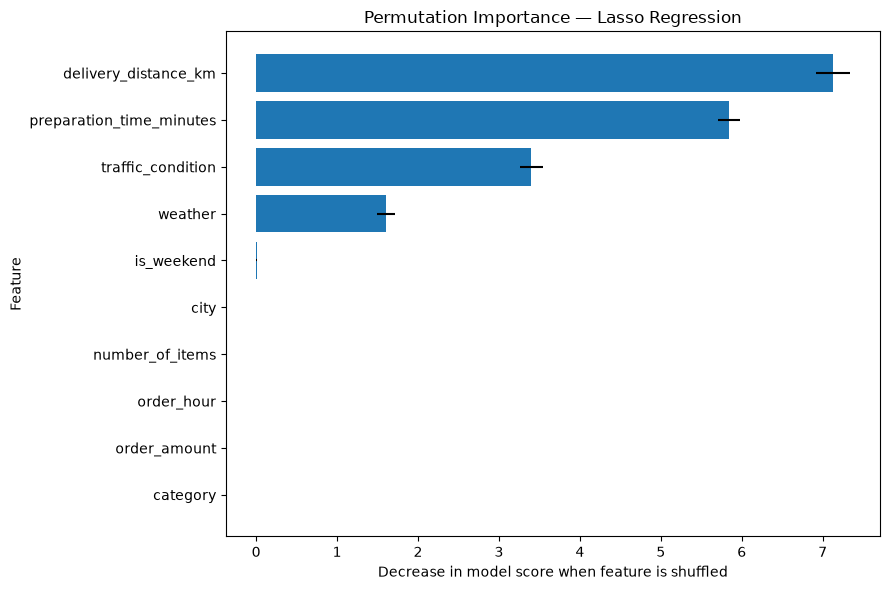

In [15]:
importance_plot = feature_importance.sort_values("Importance")

plt.figure(figsize=(9, 6))
plt.barh(
    importance_plot["Feature"],
    importance_plot["Importance"],
    xerr=importance_plot["Importance_Std"]
)

plt.xlabel("Decrease in model score when feature is shuffled")
plt.ylabel("Feature")
plt.title(f"Permutation Importance — {best_model_name}")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "delivery_time_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Business Interpretation and Recommendations

### Model Performance

The regression models were evaluated using MAE, RMSE, and R² on a held-out test dataset. The final model should be selected by comparing all three metrics against the baseline.

### Operational Insights

The feature importance results indicate which available variables were most useful for predicting delivery time in this dataset. These results can help prioritize further investigation into delivery distance, preparation time, traffic, weather, order characteristics, and restaurant attributes.

### Business Recommendations

- Use delivery-time predictions to support more informed delivery estimates, after validating model performance.
- Investigate operational factors associated with higher predicted delivery times.
- Review large prediction errors to understand where estimates are unreliable.
- Consider retraining with new data and monitoring model performance over time.
- Validate the approach using real, representative delivery records before operational deployment.

### Limitations

This project uses synthetic data, so its performance does not establish real-world delivery prediction accuracy. A random train/test split evaluates held-out observations from the same generated dataset but does not establish performance on future time periods. Feature importance indicates predictive association rather than causation.

The preparation-time feature is appropriate only if it is known at the intended prediction time. If predictions are needed before preparation starts, the model should be retrained without that feature.

In [16]:
import joblib

joblib.dump(
    best_model,
    MODELS_DIR / "delivery_time_regression_model.joblib"
)

print("Saved model:", MODELS_DIR / "delivery_time_regression_model.joblib")

Saved model: /home/nineleaps/Projects/uber-eats-intelligence/models/delivery_time_regression_model.joblib


In [17]:
best_row = results_df.iloc[0]

summary = pd.DataFrame([{
    "Selected_Model": best_model_name,
    "Selection_Criterion": "Lowest test MAE",
    "MAE_Minutes": best_row["MAE"],
    "RMSE_Minutes": best_row["RMSE"],
    "R2": best_row["R2"],
    "Training_Rows": len(X_train),
    "Testing_Rows": len(X_test)
}])

summary.to_csv(
    INSIGHTS_DIR / "delivery_time_regression_summary.csv",
    index=False
)

print(summary.round(4).to_string(index=False))
print("\nRegression summary saved.")

  Selected_Model Selection_Criterion  MAE_Minutes  RMSE_Minutes     R2  Training_Rows  Testing_Rows
Lasso Regression     Lowest test MAE       4.1213        5.1897 0.8723           4000          1000

Regression summary saved.


In [18]:
required_files = [
    PROJECT_DIR / "notebooks" / "day4_regression_analysis.ipynb",
    INSIGHTS_DIR / "regression_model_comparison.csv",
    INSIGHTS_DIR / "delivery_time_feature_importance.csv",
    INSIGHTS_DIR / "delivery_time_regression_summary.csv",
    FIGURES_DIR / "regression_model_comparison.png",
    FIGURES_DIR / "actual_vs_predicted_delivery_time.png",
    FIGURES_DIR / "delivery_time_feature_importance.png",
    PROCESSED_DIR / "delivery_time_predictions.csv",
    MODELS_DIR / "delivery_time_regression_model.joblib"
]

for path in required_files:
    status = "FOUND" if path.exists() else "MISSING"
    print(f"{status}: {path.relative_to(PROJECT_DIR)}")

FOUND: notebooks/day4_regression_analysis.ipynb
FOUND: reports/insights/regression_model_comparison.csv
FOUND: reports/insights/delivery_time_feature_importance.csv
FOUND: reports/insights/delivery_time_regression_summary.csv
FOUND: reports/figures/regression_model_comparison.png
FOUND: reports/figures/actual_vs_predicted_delivery_time.png
FOUND: reports/figures/delivery_time_feature_importance.png
FOUND: data/processed/delivery_time_predictions.csv
FOUND: models/delivery_time_regression_model.joblib
